In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
# 设置所有图片的默认显示样式
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": False,
    "font.size": 11,
})
# 图片保存到当前工作目录下的 figures 文件夹
OUT = Path("figures")
OUT.mkdir(exist_ok=True)


def standardize(ds):
    """统一坐标名称，并将经度转换到 [-180, 180)。"""
    rename = {}

    aliases = {
        "latitude": "lat",
        "longitude": "lon",
        "TIME": "time",
        "LAT": "lat",
        "LON": "lon",
    }
    # 仅重命名数据中实际存在、且目标名称尚未被使用的坐标
    for old, new in aliases.items():
        if old in ds.variables or old in ds.dims:
            if new not in ds.variables and new not in ds.dims:
                rename[old] = new

    ds = ds.rename(rename)

    if "lon" in ds.coords:
        ds = ds.assign_coords(lon=(ds.lon + 180) % 360 - 180)
        ds = ds.sortby("lon")# 经度从西到东排列

    if "lat" in ds.coords:
        ds = ds.sortby("lat")# 纬度从南到北排列

    if "time" in ds.coords:
        ds = ds.sortby("time")# 时间从早到晚排列

    return ds


def prepare_field(da):
     """检查变量是否为规则经纬度网格，并统一维度顺序。"""

    # 去掉长度为 1 的额外维度，例如只有一个气压层的 level 维度
    for dim in list(da.dims):
        if dim not in ("time", "lat", "lon") and da.sizes[dim] == 1:
            da = da.isel({dim: 0}, drop=True)

    required = {"time", "lat", "lon"}
# 如果仍有多个深度层等额外维度，需要先手动选择其中一层
    if set(da.dims) != required:
        raise ValueError(
            f"需要 time、lat、lon 三个维度，当前为 {da.dims}。"
            "请先选择深度、气压层或其他额外维度。"
        )

    if da.lat.ndim != 1 or da.lon.ndim != 1:
        raise ValueError("本代码适用于一维经纬度坐标的规则网格。")

    return da.transpose("time", "lat", "lon")


def area_mean(da):
    """规则经纬度网格的面积加权平均。"""
    # 同样经纬度间隔的网格，在高纬度的实际面积更小
    # cos(纬度) 可作为网格面积的相对权重
    weights = np.cos(np.deg2rad(da.lat))
    return da.weighted(weights).mean(("lat", "lon"), skipna=True)


def monthly_anomaly(da, reference=None):
    """逐月减去对应月份的多年平均，不去除长期趋势。"""
    # 未指定参考期时，使用 da 的全部时间计算逐月平均
    reference = da if reference is None else reference
    climatology = reference.groupby("time.month").mean("time", skipna=True)
    # 每个时间点减去它所属月份的平均值
    # 例如 2018 年 1 月减去参考期所有 1 月的平均值
    anomaly = da.groupby("time.month") - climatology
    return climatology, anomaly


def save_show(fig, filename):
     """保存并显示一张图。"""
    fig.savefig(OUT / filename, dpi=300, bbox_inches="tight")
    plt.show()

In [2]:
# Q1
ch4_file = r"C:\Users\Lenovo\Desktop\python\200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc"

ds_ch4 = standardize(xr.open_dataset(ch4_file))
print(ds_ch4)

ch4 = prepare_field(ds_ch4["xch4"])
ch4 = ch4.sel(time=slice("2003-01-01", "2020-06-30"))

<xarray.Dataset>
Dimensions:                  (time: 210, bnds: 2, lat: 36, lon: 72, pressure: 10)
Coordinates:
  * time                     (time) datetime64[ns] 2003-01-16T12:00:00 ... 20...
  * lat                      (lat) float64 -87.5 -82.5 -77.5 ... 77.5 82.5 87.5
  * lon                      (lon) float64 -177.5 -172.5 -167.5 ... 172.5 177.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] ...
    lat_bnds                 (lat, bnds) float64 ...
    lon_bnds                 (lon, bnds) float64 ...
    pre                      (pressure) float64 ...
    pre_bnds                 (pressure, bnds) float64 ...
    land_fraction            (lat, lon) float64 ...
    xch4                     (time, lat, lon) float32 ...
    xch4_nobs                (time, lat, lon) float64 ...
    xch4_stderr              (time, lat, lon) float32 ...
    xch4_stddev              (time, lat, lon) float32 ...
    column_averaging_ke

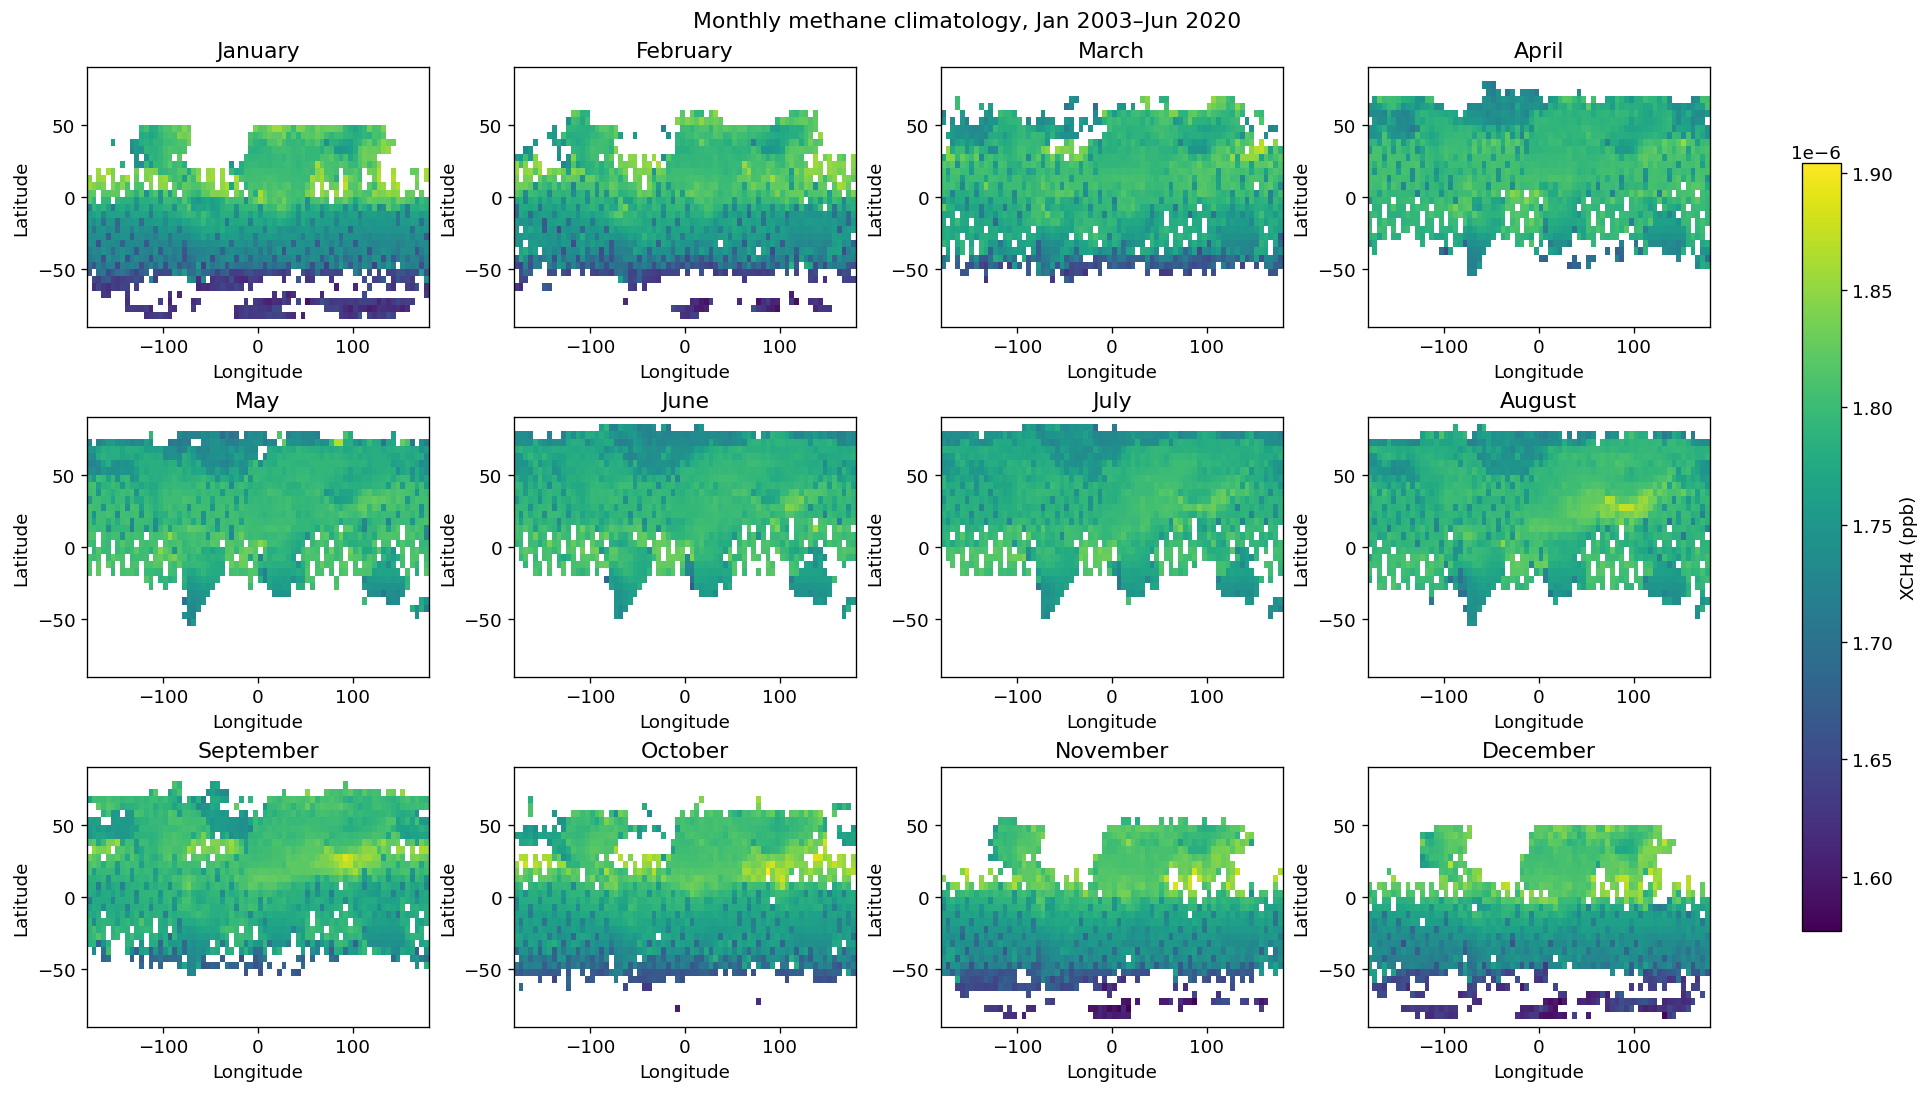

In [3]:
# Q1.1
# 计算甲烷数据的逐月平均值
ch4_clim, _ = monthly_anomaly(ch4)
# 找出全部 12 个月中的最低值和最高值
vmin = float(ch4_clim.min())
vmax = float(ch4_clim.max())

fig, axes = plt.subplots(
    3, 4, figsize=(16, 9), constrained_layout=True
)

for month, ax in enumerate(axes.flat, start=1):
    panel = ch4_clim.sel(month=month)

    im = ax.pcolormesh(
        panel.lon,
        panel.lat,
        panel,
        shading="auto",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
    )

    ax.set_title(pd.Timestamp(2000, month, 1).strftime("%B"))
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
# 为全部 12 张小图添加一条共用的颜色刻度条
fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="XCH4 (ppb)",
    shrink=0.8,
)
fig.suptitle("Monthly methane climatology, Jan 2003–Jun 2020")
save_show(fig, "1_1_ch4_monthly_climatology.png")

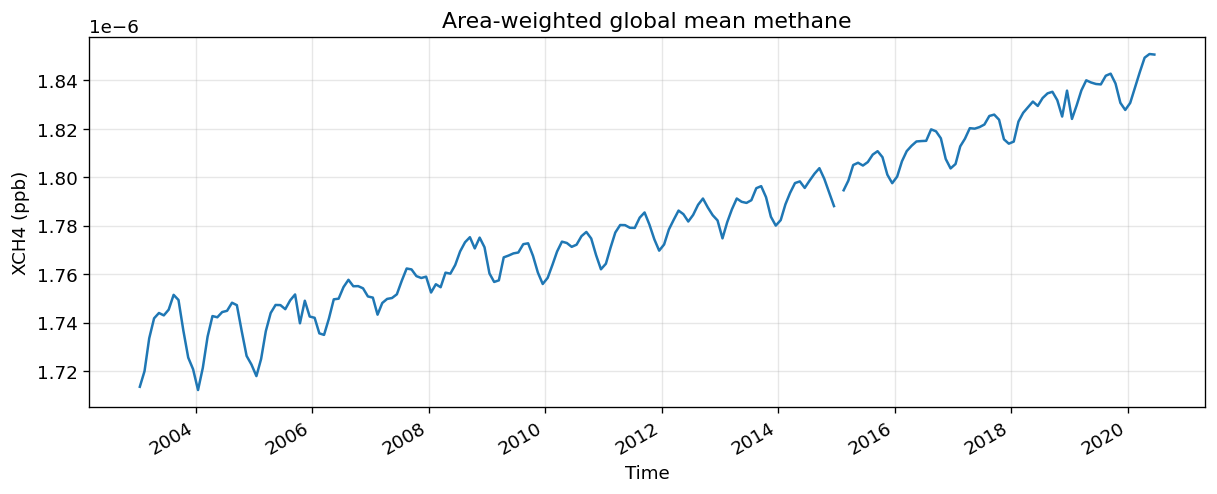

In [4]:
# Q1.2
# 对每个月的全球甲烷网格数据求面积加权平均
global_ch4 = area_mean(ch4)

fig, ax = plt.subplots(figsize=(12, 4))

global_ch4.plot(
    ax=ax,
    color="tab:blue",
    linewidth=1.5,
)

ax.set_title("Area-weighted global mean methane")
ax.set_xlabel("Time")
ax.set_ylabel("XCH4 (ppb)")
ax.grid(alpha=0.3)

save_show(fig, "1_2_global_ch4_timeseries.png")

Selected grid: lat=-12.50, lon=-147.50


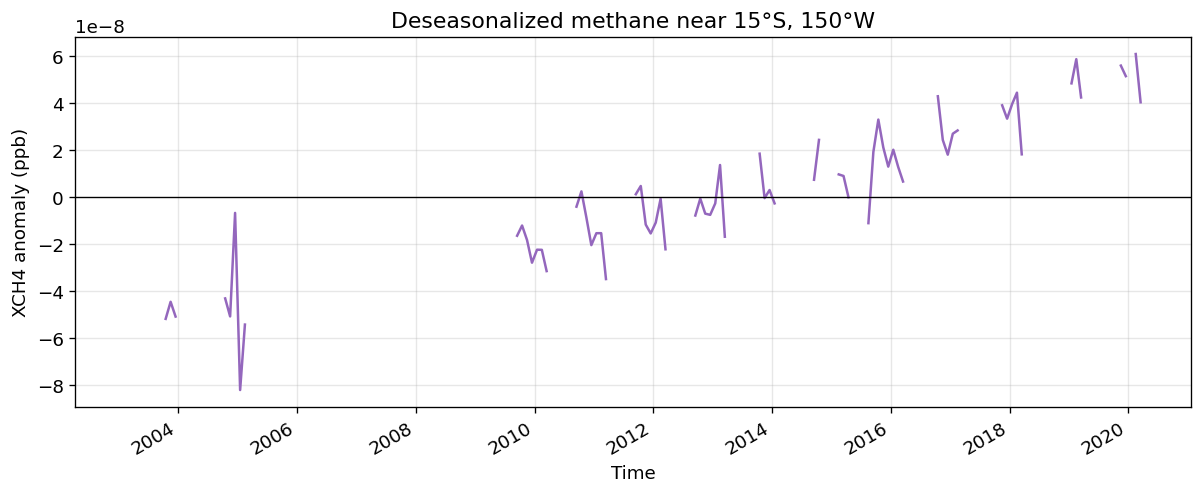

In [5]:
# Q1.3
# 指定位置去季节化
point_ch4 = ch4.sel(lat=-15, lon=-150, method="nearest")

print(
    f"Selected grid: "
    f"lat={float(point_ch4.lat):.2f}, "
    f"lon={float(point_ch4.lon):.2f}"
)
# 计算该网格点各月份的多年平均值，并从原始数据中减去
point_clim, point_anomaly = monthly_anomaly(point_ch4)

fig, ax = plt.subplots(figsize=(12, 4))

point_anomaly.plot(
    ax=ax,
    color="tab:purple",
    linewidth=1.5,
)
# 在距平等于 0 的位置画一条黑色水平线
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Deseasonalized methane near 15°S, 150°W")
ax.set_xlabel("Time")
ax.set_ylabel("XCH4 anomaly (ppb)")
ax.grid(alpha=0.3)

save_show(fig, "1_3_point_ch4_deseasonalized.png")

In [17]:
# Q2
# Q2.1
ds_sst = standardize(xr.open_dataset(r"C:\Users\Lenovo\Desktop\python\NOAA_NCDC_ERSST_v3b_SST.nc"))
print(ds_sst)

#默认使用整个数据时段计算气候态
SST_VAR = "sst"
sst = prepare_field(ds_sst[SST_VAR])

# 温标检查：温度距平以 °C 表示
units = str(sst.attrs.get("units", "")).strip().lower()

if units in {"k", "kelvin", "degree_kelvin", "degrees_kelvin"}:
    sst = sst - 273.15
    sst.attrs["units"] = "degC"

# 经度已转换为 [-180, 180)
nino_region = sst.sel(
    lat=slice(-5, 5),
    lon=slice(-170, -120),
)

if nino_region.sizes["lat"] == 0 or nino_region.sizes["lon"] == 0:
    raise ValueError("Niño 3.4 区域为空，请检查经纬度坐标。")

# 统一为连续月序列；缺失月份保留为 NaN
nino_sst = area_mean(nino_region).resample(time="MS").mean()

BASELINE = None

reference = (
    nino_sst
    if BASELINE is None
    else nino_sst.sel(time=slice(*BASELINE))
)

if reference.sizes["time"] == 0:
    raise ValueError("设定的基准期不在数据时间范围内。")

nino_clim, nino_anomaly = monthly_anomaly(nino_sst, reference)

# 居中的三个月滑动平均；缺少完整窗口时不计算
nino34 = nino_anomaly.rolling(
    time=3,
    center=True,
    min_periods=3,
).mean()

print("Monthly SST climatology:")
print(nino_clim.to_series())

<xarray.Dataset>
Dimensions:  (lat: 89, lon: 180, time: 684)
Coordinates:
  * lat      (lat) float32 -88.0 -86.0 -84.0 -82.0 -80.0 ... 82.0 84.0 86.0 88.0
  * lon      (lon) float32 -180.0 -178.0 -176.0 -174.0 ... 174.0 176.0 178.0
  * time     (time) datetime64[ns] 1960-01-15 1960-02-15 ... 2016-12-15
Data variables:
    sst      (time, lat, lon) float32 ...
Attributes:
    Conventions:  IRIDL
    source:       https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/...
    history:      extracted and cleaned by Ryan Abernathey for Research Compu...
Monthly SST climatology:
month
1     26.567791
2     26.742275
3     27.239607
4     27.693745
5     27.795218
6     27.597759
7     27.198921
8     26.824205
9     26.737831
10    26.717144
11    26.693287
12    26.613096
Name: sst, dtype: float32


Events: 3-month mean > +0.5 or < -0.5 degC for >= 5 consecutive months
  event   start     end  duration_months peak_month  peak_degC
La Nina 1962-09 1963-01                5    1962-12     -0.795
El Nino 1963-07 1964-01                7    1963-12      0.949
La Nina 1964-04 1965-01               10    1964-10     -1.246
El Nino 1965-06 1966-03               10    1965-11      1.516
La Nina 1967-10 1968-04                7    1968-02     -0.865
El Nino 1968-11 1969-05                7    1969-01      0.998
La Nina 1970-07 1972-01               19    1971-01     -1.317
El Nino 1972-06 1973-02                9    1972-12      2.010
La Nina 1973-05 1976-04               36    1973-12     -2.148
El Nino 1976-10 1977-02                5    1976-11      0.677
El Nino 1982-05 1983-06               14    1982-12      2.230
La Nina 1984-10 1985-09               12    1984-12     -1.150
El Nino 1986-09 1988-01               17    1987-09      1.554
La Nina 1988-05 1989-05               13    198

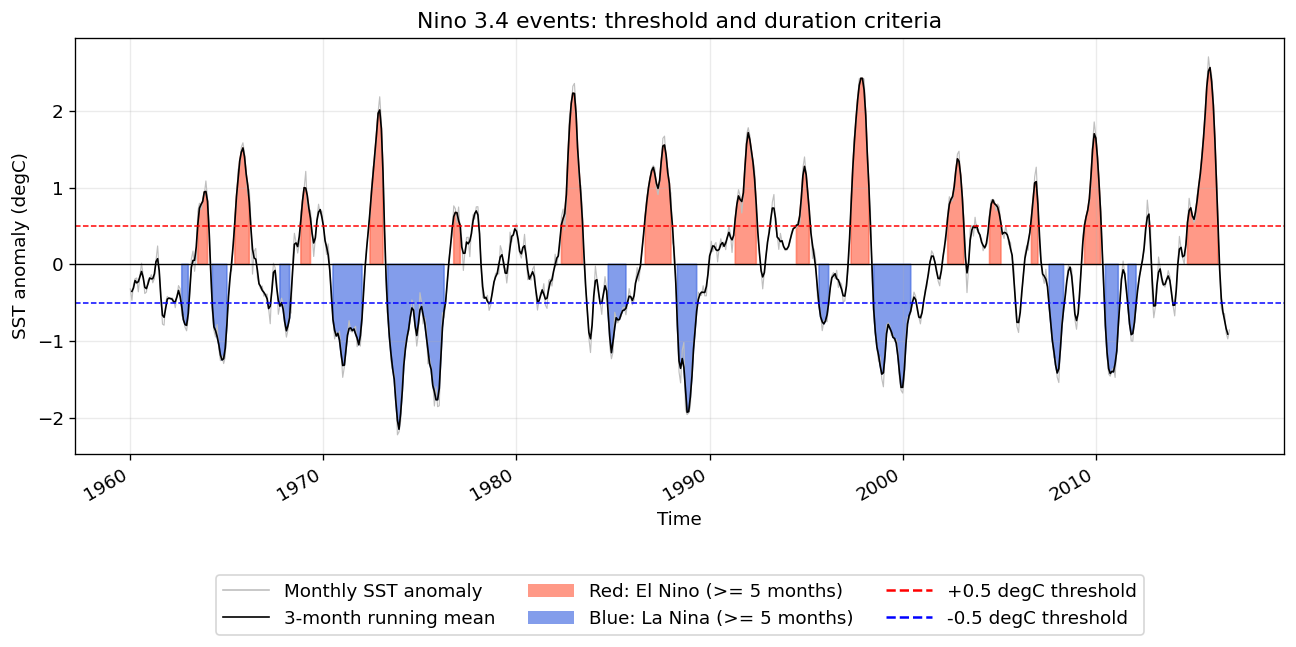

In [19]:
# Q2.2：根据已计算的 Niño 3.4 三个月滑动平均值识别事件
def identify_events(series, threshold=0.5, min_months=5):
    """识别连续达到阈值的厄尔尼诺和拉尼娜事件。"""

    series = series.copy().sort_index()

    series.index = pd.DatetimeIndex(series.index).to_period("M")

    # 同一个月份只能有一个指数值
    if series.index.has_duplicates:
        raise ValueError("输入数据中存在重复月份")

    # 补齐首月到末月之间的所有月份
    # 原来缺失的月份会变成 NaN，并中断连续事件
    series = series.reindex(
        pd.period_range(
            series.index.min(),
            series.index.max(),
            freq="M",
        )
    )

    # 给每个月标记状态.使用严格阈值：恰好等于 ±0.5°C 不算越过阈值
    state = pd.Series(
        np.where(
            series > threshold,
            1,
            np.where(series < -threshold, -1, 0),
        ),
        index=series.index,
    )

    # 状态每变化一次，就开始一个新的连续区间
    run_id = state.ne(state.shift()).cumsum()

    # 保存每个月最终确认的事件状态
    confirmed = pd.Series(
        0,
        index=series.index,
        dtype=int,
    )

    # 保存各次事件的开始、结束、持续时间和峰值
    records = []

    for _, run in state.groupby(run_id):
        sign = int(run.iloc[0])

        # 没达到阈值，或连续时间不足 5 个月，不算一次事件
        if sign == 0 or len(run) < min_months:
            continue

        # 取出这段连续事件的 Niño 3.4 指数
        values = series.loc[run.index]

        # 厄尔尼诺找最高值；拉尼娜找最低值
        peak_month = (
            values.idxmax()
            if sign == 1
            else values.idxmin()
        )

        # 将该事件持续期间的每个月标记为已确认
        confirmed.loc[run.index] = sign

        # 记录事件信息
        records.append({
            "event": "El Nino" if sign == 1 else "La Nina",
            "start": str(run.index[0]),
            "end": str(run.index[-1]),
            "duration_months": len(run),
            "peak_month": str(peak_month),
            "peak_degC": float(values.loc[peak_month]),
        })

    # 把事件记录整理成表格
    events = pd.DataFrame(
        records,
        columns=[
            "event",
            "start",
            "end",
            "duration_months",
            "peak_month",
            "peak_degC",
        ],
    )

    return events, confirmed


events, event_state = identify_events(nino34.to_series())

print(
    "Events: 3-month mean > +0.5 or < -0.5 degC "
    "for >= 5 consecutive months"
)
print(
    events.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}",
    )
)

# 将事件表格保存为 CSV
events.to_csv(
    OUT / "2_nino34_events.csv",
    index=False,
)


# Niño 3.4 时间序列图
fig, ax = plt.subplots(figsize=(13, 4.5))

# 灰线：未平滑的逐月海温距平
nino_anomaly.plot(
    ax=ax,
    color="0.75",
    linewidth=0.7,
    label="Monthly anomaly",
)

# 黑线：三个月滑动平均后的 Niño 3.4 指数
nino34.plot(
    ax=ax,
    color="black",
    linewidth=1,
    label="3-month mean",
)

times = event_state.index.to_timestamp()

values = nino34.to_series().copy()
values.index = pd.DatetimeIndex(values.index).to_period("M")
values = values.reindex(event_state.index).to_numpy()

for sign, color, label in [
    (1, "tomato", "El Nino: at least 5 months"),
    (-1, "royalblue", "La Nina: at least 5 months"),
]:
    ax.fill_between(
        times,
        0,
        values,
        where=(event_state.values == sign),
        color=color,
        alpha=0.65,
        label=label,
    )

ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(0.5, color="red", linestyle="--", linewidth=0.9)
ax.axhline(-0.5, color="blue", linestyle="--", linewidth=0.9)

ax.set(
    title="Nino 3.4 events: threshold and duration criteria",
    xlabel="Time",
    ylabel="SST anomaly (degC)",
)

# 导入自定义图例的组件
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

legend_handles = [
    Line2D(
        [0], [0],
        color="0.75",
        linewidth=1,
        label="Monthly SST anomaly",
    ),
    Line2D(
        [0], [0],
        color="black",
        linewidth=1,
        label="3-month running mean",
    ),
    Patch(
        facecolor="tomato",
        alpha=0.65,
        label="Red: El Nino (>= 5 months)",
    ),
    Patch(
        facecolor="royalblue",
        alpha=0.65,
        label="Blue: La Nina (>= 5 months)",
    ),
    Line2D(
        [0], [0],
        color="red",
        linestyle="--",
        label="+0.5 degC threshold",
    ),
    Line2D(
        [0], [0],
        color="blue",
        linestyle="--",
        label="-0.5 degC threshold",
    ),
]

ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.27),
    fontsize=11,
    ncol=3,
    frameon=True,
    columnspacing=1.8,
    handlelength=2.5,
)

ax.grid(alpha=0.25)

save_show(fig, "2_nino34_events.png")

In [8]:
# Q3
# 项目根目录
ROOT = Path(r"C:\Users\Lenovo\Documents\New project")

# GPCP 原始数据所在的文件夹
DATA_DIR = ROOT / "gpcp_data" / "nasa_earthaccess_original"

# 图片的保存文件夹
OUT = ROOT / "outputs" / "assignment03_gpcp" / "figures"
OUT.mkdir(parents=True, exist_ok=True)  

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
})


def save_show(fig, name):
    """保存、显示并关闭一张图。"""

    fig.savefig(
        OUT / name,
        dpi=200,
        bbox_inches="tight",  
    )
    plt.show()
    plt.close(fig)  


# 找出目录中所有符合名称格式的 GPCP 月度文件，并排序
files = sorted(DATA_DIR.glob("GPCPMON_L3_*_V3.3.nc4"))

# 没有找到文件时，立即报错
if not files:
    raise FileNotFoundError(f"在 {DATA_DIR} 中没有找到 GPCP 文件")

pieces = []

# 逐个读取文件，只提取卫星与雨量站融合降水变量
for file in files:
    with xr.open_dataset(file) as ds:
        # load() 先将该变量读入内存
        # 离开 with 代码块后，原始文件就可以关闭
        pieces.append(ds["sat_gauge_precip"].load())

# 将各个月的数据沿时间维度合并
# join="exact" 要求不同文件的空间网格坐标完全一致
# 随后按时间和纬度排序
precip = (
    xr.concat(pieces, dim="time", join="exact")
    .sortby("time")
    .sortby("lat")
)

# 降水量不应为负；将负值设为缺测值 NaN
precip = precip.where(precip >= 0)

# 提取每个文件的时间，并转换为“年-月”格式
dates = pd.DatetimeIndex(precip.time.values)
periods = dates.to_period("M")

# 生成从第一个月到最后一个月的完整月份列表
expected = pd.period_range(
    periods.min(),
    periods.max(),
    freq="M",
)

# 检查是否存在重复月份或缺失月份
if periods.has_duplicates or not periods.equals(expected):
    raise ValueError("存在重复或缺失的月份，请检查输入文件")

# 统计 1—12 月各出现了多少次
month_counts = (
    pd.Series(dates.month)
    .value_counts()
    .reindex(range(1, 13), fill_value=0)
)

# 后面需要计算逐月平均，因此每个日历月至少要有两个年份的数据
if (month_counts < 2).any():
    raise ValueError("每个日历月至少需要两个年份的观测数据")

print(f"已读取 {len(files)} 个文件：{dates[0]:%Y-%m} 至 {dates[-1]:%Y-%m}")
print("变量：sat_gauge_precip；单位：mm/day（月平均降水率）")
print("有效数据比例：", float(precip.notnull().mean()))

已读取 36 个文件：2017-01 至 2019-12
变量：sat_gauge_precip；单位：mm/day（月平均降水率）
有效数据比例： 1.0


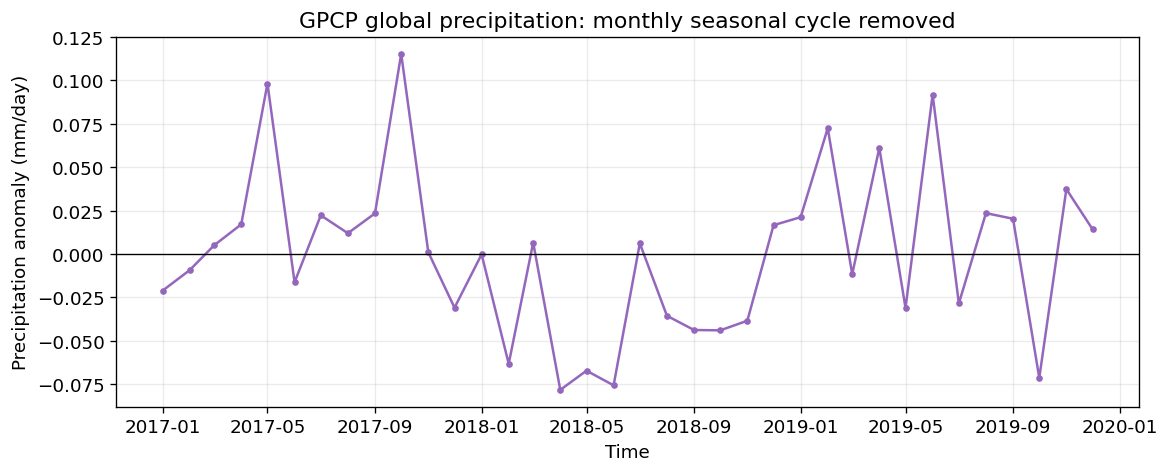

In [9]:
# 3.1：绘制去除月季节循环后的全球平均降水时间序列
# 用 cos(纬度) 作为各纬度网格的相对面积权重
weights = np.cos(np.deg2rad(precip.lat))

# 对每个月的全球网格求面积加权平均
global_mean = precip.weighted(weights).mean(
    ("lat", "lon"),
    skipna=True,  
)

# 将所有年份的同一个月份放在一起求平均
climatology = global_mean.groupby("time.month").mean("time")

# 每个月的原始值减去对应月份的气候态
anomaly = global_mean.groupby("time.month") - climatology

# 检查计算结果：同一个日历月的距平平均值应接近 0
# atol=1e-5 允许浮点计算产生极小的误差
np.testing.assert_allclose(
    anomaly.groupby("time.month").mean("time").values,
    0,
    atol=1e-5,
)


fig, ax = plt.subplots(figsize=(11, 4))

# 绘制逐月距平时间序列
ax.plot(
    dates,
    anomaly.values,
    "o-",                # 每个月显示一个圆点，并用线连接
    markersize=3,
    color="tab:purple",
)

# 画一条距平为 0 的参考线
ax.axhline(0, color="black", linewidth=0.8)

ax.set(
    title="GPCP global precipitation: monthly seasonal cycle removed",
    xlabel="Time",
    ylabel="Precipitation anomaly (mm/day)",
)

ax.grid(alpha=0.25)

save_show(fig, "3_1_deseasonalized.png")

# 将画图所用的数值保存为 CSV，便于检查或制作报告表格
pd.DataFrame({
    "time": dates,
    "global_mean_mm_day": global_mean.values,
    "monthly_climatology_mm_day": climatology.sel(
        month=global_mean.time.dt.month
    ).values,
    "anomaly_mm_day": anomaly.values,
}).to_csv(
    OUT.parent / "global_precipitation.csv",
    index=False,  # 不额外保存 DataFrame 的行号
)

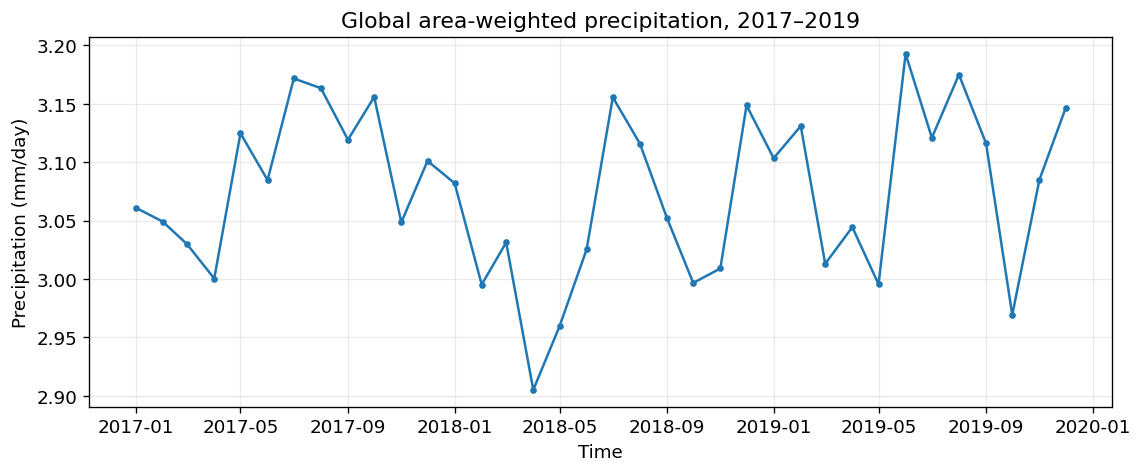

In [11]:
# 3.2 图 1：绘制全球平均降水的原始月度时间序列
fig, ax = plt.subplots(figsize=(11, 4))
# 每个月画一个圆点，并用线连接
ax.plot(dates, global_mean.values, "o-", markersize=3)
ax.set(title="Global area-weighted precipitation, 2017–2019",
       xlabel="Time", ylabel="Precipitation (mm/day)")
ax.grid(alpha=0.25)
save_show(fig, "3_2_1_global_timeseries.png")

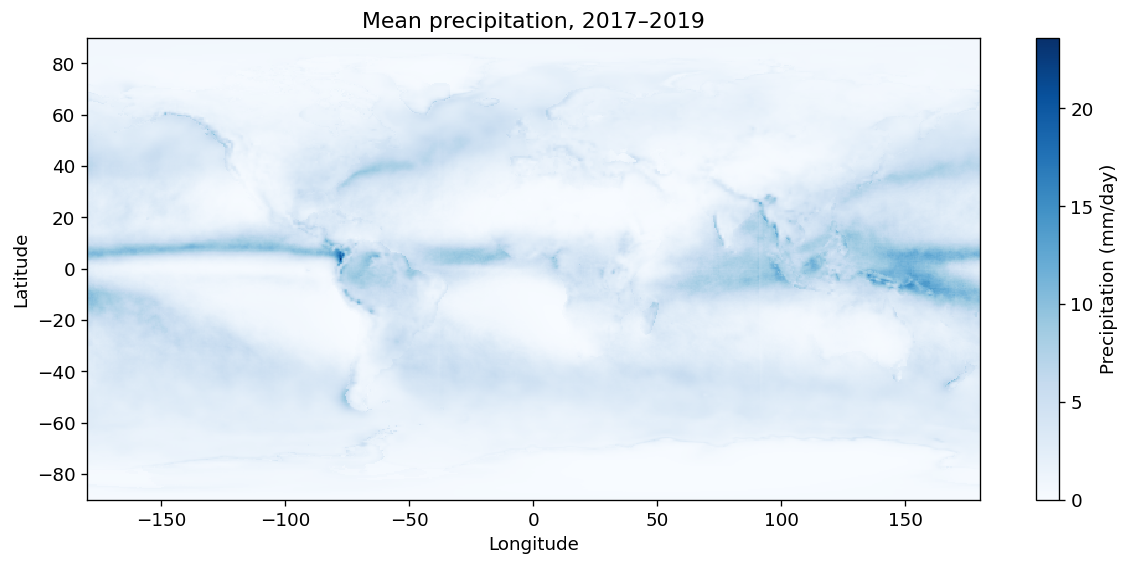

In [12]:
# 3.2 图 2：绘制 2017—2019 年的全球平均降水分布图
# 对每个网格点的 36 个月降水值求平均
# 每个月在计算中占相同权重
mean_map = precip.mean("time")
fig, ax = plt.subplots(figsize=(12, 5))
mean_map.plot.pcolormesh(
    ax=ax, x="lon", y="lat", cmap="Blues", vmin=0,
    cbar_kwargs={"label": "Precipitation (mm/day)"},
)
ax.set(title="Mean precipitation, 2017–2019", xlabel="Longitude", ylabel="Latitude")
save_show(fig, "3_2_2_mean_map.png")

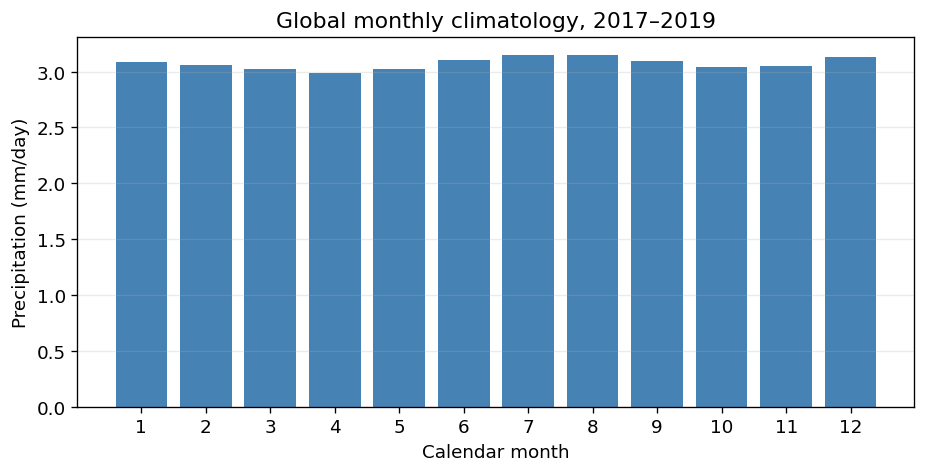

In [13]:
# 3.2 图 3：绘制全球平均降水的逐月季节变化
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(np.arange(1, 13), climatology.values, color="steelblue")
ax.set_xticks(np.arange(1, 13))
ax.set(title="Global monthly climatology, 2017–2019",
       xlabel="Calendar month", ylabel="Precipitation (mm/day)")
ax.grid(axis="y", alpha=0.25)
save_show(fig, "3_2_3_monthly_climatology.png")

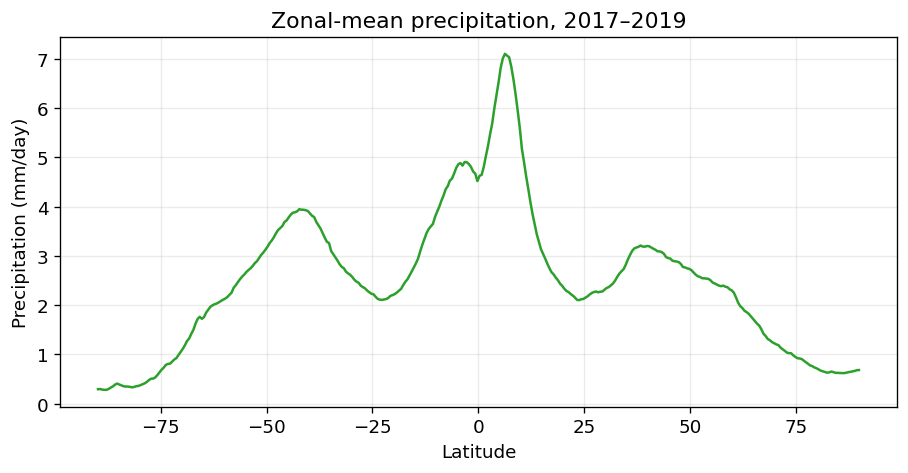

In [14]:
# 3.2 图 4：绘制平均降水随纬度变化的曲线
# 对每个纬度上的所有经度网格求平均
# 同一纬度上的各经度网格权重相同；缺测值不参与平均
zonal_mean = mean_map.mean("lon", skipna=True)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(zonal_mean.lat, zonal_mean, color="tab:green")
ax.set(title="Zonal-mean precipitation, 2017–2019",
       xlabel="Latitude", ylabel="Precipitation (mm/day)")
ax.grid(alpha=0.25)
save_show(fig, "3_2_4_latitude_profile.png")

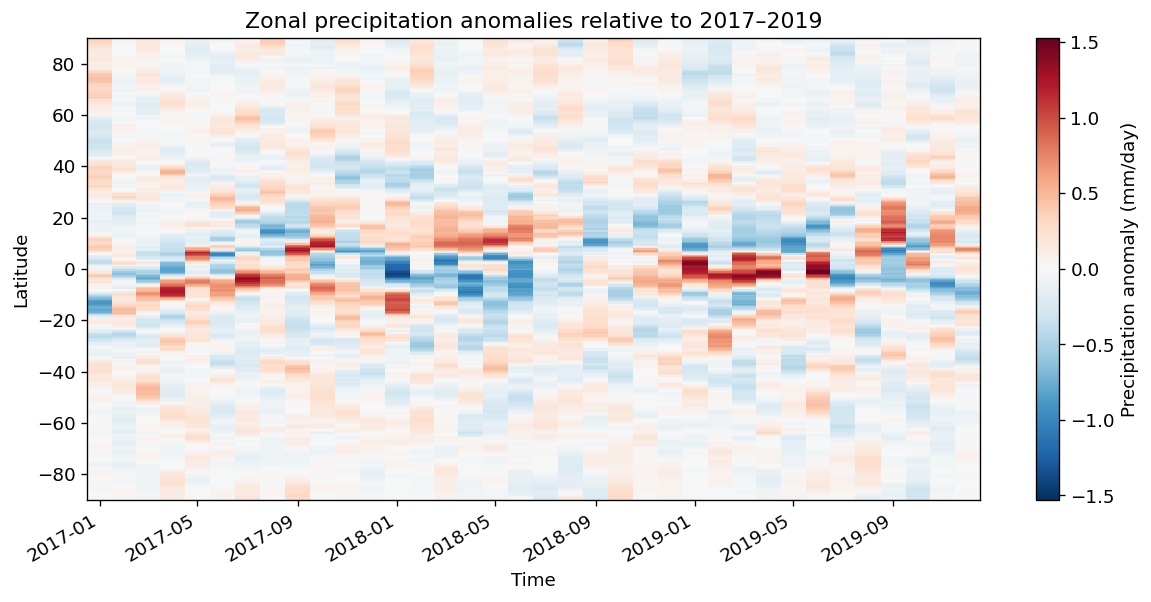

Figures saved to: C:\Users\Lenovo\Documents\New project\outputs\assignment03_gpcp\figures


In [15]:
# 3.2 图 5：绘制降水距平随时间和纬度变化的热力图
# 对每个月、每个纬度上的所有经度网格求平均
# 结果保留“时间”和“纬度”两个维度
zonal = precip.mean("lon", skipna=True)
# 分别计算每个日历月在各纬度的三年平均降水率
zonal_clim = zonal.groupby("time.month").mean("time")
zonal_anomaly = zonal.groupby("time.month") - zonal_clim
limit = float(np.abs(zonal_anomaly).max())
fig, ax = plt.subplots(figsize=(12, 5))
zonal_anomaly.plot.pcolormesh(
    ax=ax, x="time", y="lat", cmap="RdBu_r", vmin=-limit, vmax=limit,
    cbar_kwargs={"label": "Precipitation anomaly (mm/day)"},
)
ax.set(title="Zonal precipitation anomalies relative to 2017–2019",
       xlabel="Time", ylabel="Latitude")
save_show(fig, "3_2_5_time_latitude_anomalies.png")
print("Figures saved to:", OUT)

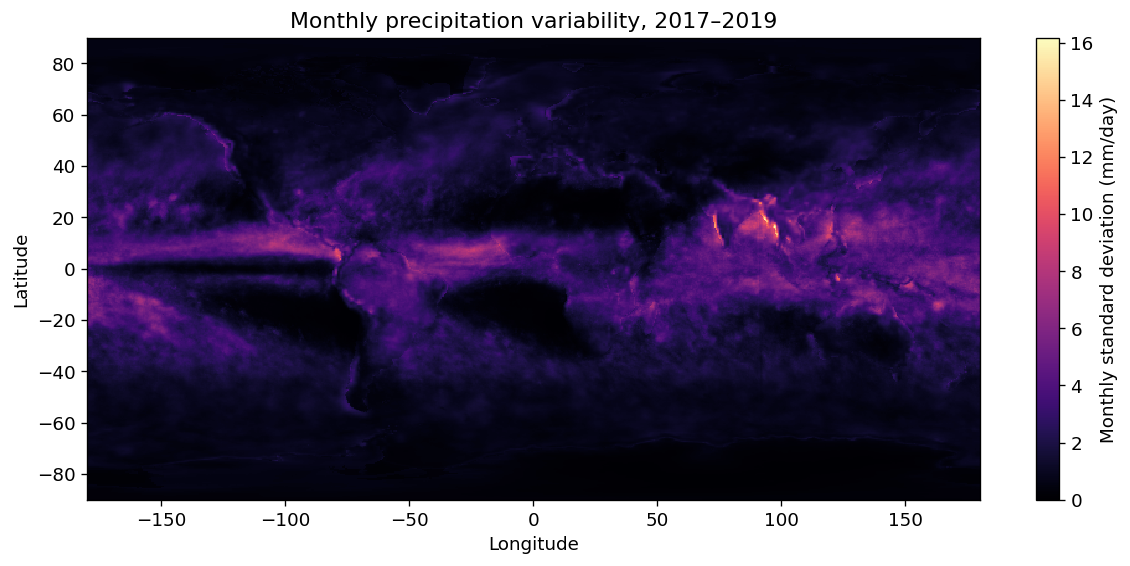

In [16]:
# 3.2 图 6：各网格点月降水的标准差
monthly_std = precip.std("time")

fig, ax = plt.subplots(figsize=(12, 5))
monthly_std.plot.pcolormesh(
    ax=ax,
    x="lon",
    y="lat",
    cmap="magma",
    vmin=0,
    cbar_kwargs={"label": "Monthly standard deviation (mm/day)"},
)

ax.set(
    title="Monthly precipitation variability, 2017–2019",
    xlabel="Longitude",
    ylabel="Latitude",
)
save_show(fig, "3_2_6_monthly_variability_map.png")